In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm
import sklearn.linear_model as lm
sns.set()

url = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"
dat = pd.read_csv(url)
dat.head()

,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,2/28/23,3/1/23,3/2/23,3/3/23,3/4/23,3/5/23,3/6/23,3/7/23,3/8/23,3/9/23
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0,0,0,...,209322,209340,209358,209362,209369,209390,209406,209436,209451,209451
1,NaN,Albania,41.15330,20.168300,0,0,0,0,0,0,...,334391,334408,334408,334427,334427,334427,334427,334427,334443,334457
2,NaN,Algeria,28.03390,1.659600,0,0,0,0,0,0,...,271441,271448,271463,271469,271469,271477,271477,271490,271494,271496
3,NaN,Andorra,42.50630,1.521800,0,0,0,0,0,0,...,47866,47875,47875,47875,47875,47875,47875,47875,47890,47890
4,NaN,Angola,-11.20270,17.873900,0,0,0,0,0,0,...,105255,105277,105277,105277,105277,105277,105277,105277,105288,105288


### Question 1: Setup and modeling choices

**Country.** I used Japan, which appears as a single row in the file. t = 0 is the first date in the file (1/22/20), because Japan already had cases on that date.

**Definition of Y_t.** The file contains cumulative confirmed cases (a running total). I defined Y_t as daily new cases, the day-to-day difference of the cumulative counts (`np.diff`) rather than the cumulative counts (Y = cumulative). I chose this because:
1. Question 4 asks whether cases go "up or down." Japan's running total never decreases (0 of 1,142 days), and new cases were reported on all but 10 days, so a "went up" indicator built from the running total would be 1 on almost every day. Daily counts move in both directions.
2. With the running total, the five lagged predictors are nearly identical (pairwise correlations above 0.9998). With daily counts they are still highly correlated (at least 0.89), but less so, so individual coefficients should be interpreted cautiously.

**Indexing.** Because `np.diff` takes the change from one day to the next, the first daily value is the change from day 0 to day 1, so the series Y_t starts at t = 1 (1,142 daily values from 1,143 days of cumulative counts). The regression then uses t = 6 through t = 1142 (1,137 rows), because the first five daily values are needed as lags.

A comparison using the cumulative counts is in the code cell just above the report table.

1 row selected


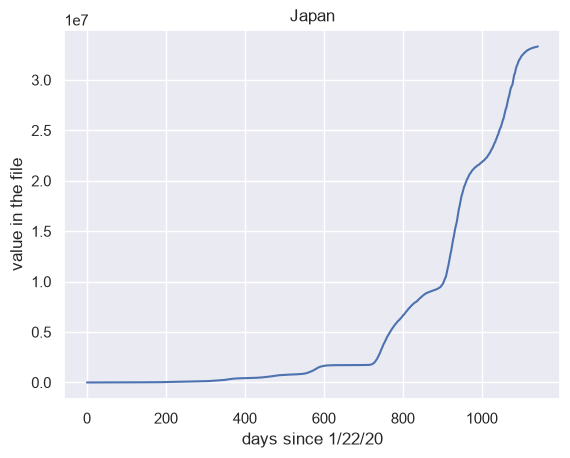

In [2]:
country = "Japan"

row = dat[dat["Country/Region"] == country]
print(len(row), "row selected")
counts = row.iloc[0, 4:].astype(float).values
plt.plot(counts)
plt.xlabel("days since 1/22/20")
plt.ylabel("value in the file")
plt.title(country)
plt.show()

In [3]:
onset = np.argmax(counts > 0)
cumulative = counts[onset:]

print("onset position:", onset)
print("days since onset:", len(cumulative))
print(cumulative[:6])

Y = np.diff(cumulative)    

print(len(Y))
print(Y[:10])

onset position: 0
days since onset: 1143
[2. 2. 2. 2. 4. 4.]
1142
[0. 0. 0. 2. 0. 3. 0. 4. 4. 5.]


In [4]:
lagdat = pd.DataFrame({"Y": Y})
lagdat["Y_lag1"] = lagdat["Y"].shift(1)
lagdat["Y_lag2"] = lagdat["Y"].shift(2)
lagdat["Y_lag3"] = lagdat["Y"].shift(3)
lagdat["Y_lag4"] = lagdat["Y"].shift(4)
lagdat["Y_lag5"] = lagdat["Y"].shift(5)

lagdat = lagdat.dropna().reset_index(drop=True)
print(lagdat.head())
print(len(lagdat))

results = smf.ols('Y ~ Y_lag1 + Y_lag2 + Y_lag3 + Y_lag4 + Y_lag5', data=lagdat).fit()
print(results.summary2())
print(lagdat[["Y_lag1", "Y_lag2", "Y_lag3", "Y_lag4", "Y_lag5"]].corr())

     Y  Y_lag1  Y_lag2  Y_lag3  Y_lag4  Y_lag5
0  3.0     0.0     2.0     0.0     0.0     0.0
1  0.0     3.0     0.0     2.0     0.0     0.0
2  4.0     0.0     3.0     0.0     2.0     0.0
3  4.0     4.0     0.0     3.0     0.0     2.0
4  5.0     4.0     4.0     0.0     3.0     0.0
1137
                  Results: Ordinary least squares
Model:              OLS              Adj. R-squared:     0.917     
Dependent Variable: Y                AIC:                25056.4611
Date:               2026-11-07 21:26 BIC:                25086.6780
No. Observations:   1137             Log-Likelihood:     -12522.   
Df Model:           5                F-statistic:        2509.     
Df Residuals:       1131             Prob (F-statistic): 0.00      
R-squared:          0.917            Scale:              2.1674e+08
--------------------------------------------------------------------
            Coef.    Std.Err.     t     P>|t|     [0.025     0.975] 
-------------------------------------------------

In [5]:
lag_cum = pd.DataFrame({"Y": cumulative})
lag_cum["Y_lag1"] = lag_cum["Y"].shift(1)
lag_cum["Y_lag2"] = lag_cum["Y"].shift(2)
lag_cum["Y_lag3"] = lag_cum["Y"].shift(3)
lag_cum["Y_lag4"] = lag_cum["Y"].shift(4)
lag_cum["Y_lag5"] = lag_cum["Y"].shift(5)
lag_cum = lag_cum.dropna().reset_index(drop=True)

results_cum = smf.ols('Y ~ Y_lag1 + Y_lag2 + Y_lag3 + Y_lag4 + Y_lag5', data=lag_cum).fit()
print(results_cum.params)
print("R squared:", results_cum.rsquared)

Intercept    669.240225
Y_lag1         1.842501
Y_lag2        -1.052316
Y_lag3         0.450341
Y_lag4        -0.149817
Y_lag5        -0.090646
dtype: float64
R squared: 0.9999977124600801


In [6]:
ci = results.conf_int()
report = pd.DataFrame({"coefficient": results.params,
                       "std error": results.bse,
                       "lower 95%": ci[0],
                       "upper 95%": ci[1],
                       "p-value": results.pvalues})
print(report.round(4))

           coefficient  std error  lower 95%  upper 95%  p-value
Intercept     718.9519   507.5205  -276.8355  1714.7394   0.1569
Y_lag1          0.8290     0.0294     0.7714     0.8866   0.0000
Y_lag2         -0.2465     0.0383    -0.3216    -0.1713   0.0000
Y_lag3          0.2743     0.0382     0.1994     0.3491   0.0000
Y_lag4         -0.0387     0.0383    -0.1139     0.0365   0.3129
Y_lag5          0.1579     0.0294     0.1003     0.2155   0.0000


In [7]:
print("days the running total decreased:", (np.diff(cumulative) < 0).sum())
print("days with zero new cases:", (Y == 0).sum())
lag_names = ["Y_lag1", "Y_lag2", "Y_lag3", "Y_lag4", "Y_lag5"]
print("smallest pairwise correlation (daily lags):", lagdat[lag_names].corr().values.min())
print("smallest pairwise correlation (cumulative lags):", lag_cum[lag_names].corr().values.min())
print("sum of lag coefficients:", results.params[lag_names].sum())
print("Y_lag2 alone:", smf.ols('Y ~ Y_lag2', data=lagdat).fit().params["Y_lag2"])
print("Y_lag2 with Y_lag1:", smf.ols('Y ~ Y_lag1 + Y_lag2', data=lagdat).fit().params["Y_lag2"])
print("Y_lag2 with all five lags:", results.params["Y_lag2"])

days the running total decreased: 0
days with zero new cases: 10
smallest pairwise correlation (daily lags): 0.8951975662069678
smallest pairwise correlation (cumulative lags): 0.9998723610443774
sum of lag coefficients: 0.9760074943629187
Y_lag2 alone: 0.9095957507956864
Y_lag2 with Y_lag1: 0.05970599702470112
Y_lag2 with all five lags: -0.24646069600256176


### Question 1: Results and interpretation

I modeled Japan's daily new cases (Y_t) as a linear function of the previous five days:
Y_t = α₀ + β₁Y_{t-1} + β₂Y_{t-2} + β₃Y_{t-3} + β₄Y_{t-4} + β₅Y_{t-5} + ε_t.
The model used 1,137 days, and R² = 0.917.

**Interpretation of each coefficient.** Each coefficient is the expected change in today's new cases for one additional new case on that earlier day, holding the other four lags constant.

- **Y_{t-1} (0.829):** Yesterday's count (day t−1) has by far the largest weight. 1,000 more cases on day t−1 goes with about 829 more cases on day t, with the other lags unchanged.
- **Y_{t-2} (-0.247):** Negative, even though the number of cases two days ago is strongly positively related to today's number on its own. Alone, its coefficient is +0.910; with Y_{t-1} added it is +0.060; with all five lags it is -0.247. A coefficient here measures what a lag adds beyond the others, and the lags overlap heavily, so this should not be read as "more cases two days ago lowers cases today."
- **Y_{t-3} (0.274) and Y_{t-5} (0.158):** Positive, with intervals that exclude zero, so these days still add information once the other lags are included.
- **Y_{t-4} (-0.039):** Its interval includes zero (p = 0.313), so the data cannot distinguish it from no contribution.
- **Intercept (719):** The predicted count if all five previous days were zero. It is not distinguishable from zero (p = 0.157) and is not a meaningful quantity on its own.

**Comparison with cumulative counts.** Using the cumulative counts as Y gives Y_{t-1} = 1.8425 and Y_{t-2} = -1.0523, with R² near 1 and lag correlations above 0.9998. The coefficients are nearly uninterpretable individually, which supports using daily new cases.

**Caution.** The lagged predictors are highly correlated, so individual coefficients should be read with care, and these are associations used for prediction, not causal effects.

**Overall.** The five coefficients sum to 0.976, so a one-case increase across all five previous days goes with an expected increase of about 0.98 cases today. The recent past predicts the present almost one-for-one, with yesterday's count (day t−1) carrying most of the weight.

### Question 2: Setup and error plots

**Definition.** Prediction error = actual − predicted new cases. Part (a) fits the lag model on all of Japan (days 6 to 1142) and applies it to the same days. Part (b) fits on the first half (days 6 to 573, 568 rows) and applies it to the second half (days 574 to 1142, 569 rows).

In [8]:
lagdat["day"] = lagdat.index + 6
half = len(lagdat) // 2
model_all = smf.ols('Y ~ Y_lag1 + Y_lag2 + Y_lag3 + Y_lag4 + Y_lag5', data=lagdat).fit()
lagdat["error_a"] = lagdat["Y"] - model_all.predict(lagdat)
mse_a = (lagdat["error_a"] ** 2).mean()

print("MSE, fit on all of Japan and applied to all of Japan:", mse_a)
print("square root of MSE:", np.sqrt(mse_a))

MSE, fit on all of Japan and applied to all of Japan: 215595319.12185872
square root of MSE: 14683.164479152943


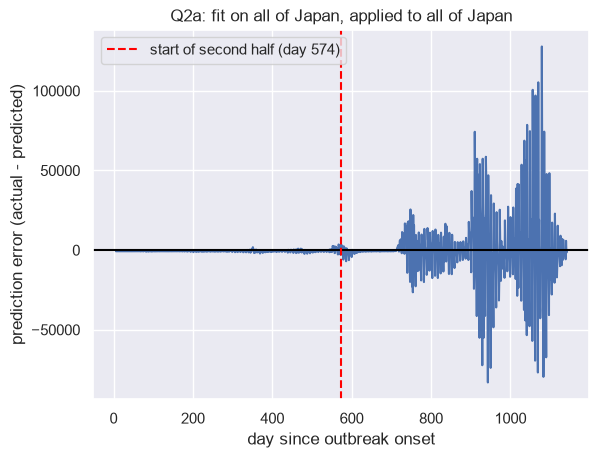

In [9]:
plt.plot(lagdat["day"], lagdat["error_a"])
plt.axhline(0, color="black")
plt.axvline(lagdat["day"].iloc[half], linestyle="--", color="red",
            label="start of second half (day " + str(lagdat["day"].iloc[half]) + ")")
plt.xlabel("day since outbreak onset")
plt.ylabel("prediction error (actual - predicted)")
plt.title("Q2a: fit on all of Japan, applied to all of Japan")
plt.legend()
plt.show()

In [10]:
trainingDat = lagdat.iloc[:half]
testingDat = lagdat.iloc[half:]
print(len(trainingDat), len(testingDat))

model_half = smf.ols('Y ~ Y_lag1 + Y_lag2 + Y_lag3 + Y_lag4 + Y_lag5', data=trainingDat).fit()

error_b = testingDat["Y"] - model_half.predict(testingDat)
mse_b = (error_b ** 2).mean()

print("MSE, fit on first half and applied to second half:", mse_b)
print("square root of MSE:", np.sqrt(mse_b))

568 569
MSE, fit on first half and applied to second half: 527829034.492244
square root of MSE: 22974.53012560309


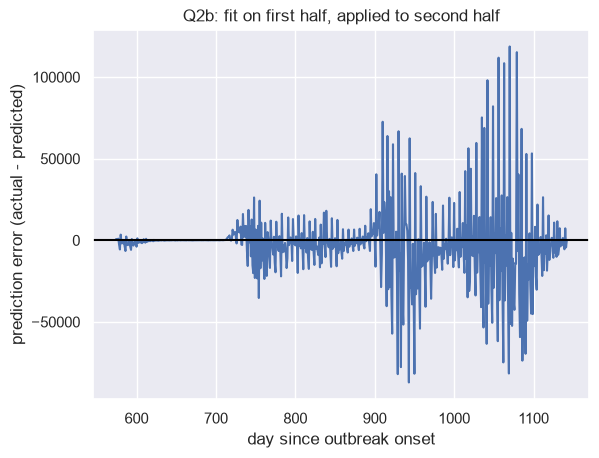

In [11]:
plt.plot(testingDat["day"], error_b)
plt.axhline(0, color="black")
plt.xlabel("day since outbreak onset")
plt.ylabel("prediction error (actual - predicted)")
plt.title("Q2b: fit on first half, applied to second half")
plt.show()

In [12]:
print("training mean and max of Y:", trainingDat["Y"].mean(), trainingDat["Y"].max())
print("testing mean and max of Y:", testingDat["Y"].mean(), testingDat["Y"].max())

mse_a_second = (lagdat["error_a"].iloc[half:] ** 2).mean()
print("MSE (a) on second half only:", mse_a_second)

training mean and max of Y: 2086.2359154929577 20496.0
testing mean and max of Y: 56477.06854130053 260999.0
MSE (a) on second half only: 430021437.1266246


### Question 2: Results and interpretation

Prediction error = actual − predicted new cases. Part (a) fits the model on all of Japan and applies it to the same days; part (b) fits on the first half (days 6 to 573) and applies it to the second half (days 574 to 1142).

MSE for (a) is about 2.16 × 10⁸ and for (b) about 5.28 × 10⁸. Part (a) is optimistic because the model is tested on the same days it was fit on. Part (b) is tested on days the model was not fit on, but the two halves also differ greatly in level: average daily new cases were about 2,086 in the first half and about 56,477 in the second, and the first-half maximum was 20,496 against 260,999 in the second half. The model fit on the first half therefore has to predict much larger counts than it was trained on. On the same second-half days, the model fit on all of Japan has an MSE of about 4.30 × 10⁸, so much of the gap between (a) and (b) comes from (a) also averaging in the quiet first half.

### Question 3: Setup and error plot

**Second country.** B is Germany, which appears as a single row in the file. I processed it exactly as in Question 1: t = 0 is Germany's first day with more than 0 cases (1/27/20), Y_t is daily new cases (`np.diff`), and each row uses the previous five days as lags. This gives 1,137 daily values and 1,132 usable rows (t = 6 through t = 1137).

**Model.** I did not refit anything. I applied `model_all`, the model fit on all of Japan in Question 2(a), to Germany's lagged data. Prediction error = actual − predicted new cases.

In [13]:
countryB = "Germany"

rowB = dat[dat["Country/Region"] == countryB]
print(len(rowB), "row selected")

countsB = rowB.iloc[0, 4:].astype(float).values
onsetB = np.argmax(countsB > 0)
cumulativeB = countsB[onsetB:]
YB = np.diff(cumulativeB)

print("onset position:", onsetB)
print("onset date:", dat.columns[4 + onsetB])
print("days since onset:", len(cumulativeB))
print(cumulativeB[:6])
print(len(YB))
print(YB[:10])

lagdatB = pd.DataFrame({"Y": YB})
lagdatB["Y_lag1"] = lagdatB["Y"].shift(1)
lagdatB["Y_lag2"] = lagdatB["Y"].shift(2)
lagdatB["Y_lag3"] = lagdatB["Y"].shift(3)
lagdatB["Y_lag4"] = lagdatB["Y"].shift(4)
lagdatB["Y_lag5"] = lagdatB["Y"].shift(5)

lagdatB = lagdatB.dropna().reset_index(drop=True)
lagdatB["day"] = lagdatB.index + 6
print(len(lagdatB))

1 row selected
onset position: 5
onset date: 1/27/20
days since onset: 1138
[1. 4. 4. 4. 5. 8.]
1137
[3. 0. 0. 1. 3. 2. 2. 0. 0. 0.]
1132


In [14]:
lagdatB["error_q3"] = lagdatB["Y"] - model_all.predict(lagdatB)
mse_q3 = (lagdatB["error_q3"] ** 2).mean()

print("MSE, Japan's model applied to Germany:", mse_q3)
print("square root of MSE:", np.sqrt(mse_q3))

MSE, Japan's model applied to Germany: 3129065113.202462
square root of MSE: 55938.047098575604


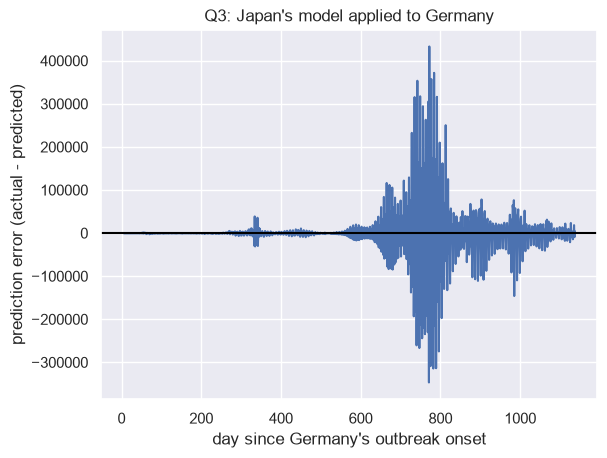

In [15]:
plt.plot(lagdatB["day"], lagdatB["error_q3"])
plt.axhline(0, color="black")
plt.xlabel("day since Germany's outbreak onset")
plt.ylabel("prediction error (actual - predicted)")
plt.title("Q3: Japan's model applied to Germany")
plt.show()

### Question 3: Results and interpretation

Applying Japan's model to Germany gives an MSE of about 3.13 × 10⁹, which is an RMSE (square root of the MSE) of about 55,900 cases per day. The plot shows errors near zero for the first several hundred days and very large swings, in both directions, around days 600 to 900. This MSE should not be compared directly with Question 2's, which were computed on Japan's data.

### Question 4: Setup and logistic model

**Definition.** Z_t = 1 if Y_t > Y_{t-1} (daily new cases went up on day t) and 0 otherwise, using Japan's daily new cases from Question 1. A day with no change counts as not up (7 days in the series). Z_t needs Y_{t-1}, so it is defined from t = 2 (1,141 values). Using five lags of Z, the model is fit on t = 7 through t = 1142 (1,136 rows):

logit P(Z_t = 1) = α₀ + β₁Z_{t-1} + β₂Z_{t-2} + β₃Z_{t-3} + β₄Z_{t-4} + β₅Z_{t-5}

I fit it by maximum likelihood with `smf.logit`, the formula version of the logistic regression in deck 22.

In [16]:
Z = (Y[1:] > Y[:-1]).astype(int)    # 1 if cases went up compared with the day before

print(len(Z))
print(Z[:15])

zdat = pd.DataFrame({"Z": Z})
zdat["Z_lag1"] = zdat["Z"].shift(1)
zdat["Z_lag2"] = zdat["Z"].shift(2)
zdat["Z_lag3"] = zdat["Z"].shift(3)
zdat["Z_lag4"] = zdat["Z"].shift(4)
zdat["Z_lag5"] = zdat["Z"].shift(5)

zdat = zdat.dropna().reset_index(drop=True).astype(int)
zdat["day"] = zdat.index + 7
print(zdat.head())
print(len(zdat))

1141
[0 0 1 0 1 0 1 0 1 0 0 1 0 0 0]
   Z  Z_lag1  Z_lag2  Z_lag3  Z_lag4  Z_lag5  day
0  0       1       0       1       0       0    7
1  1       0       1       0       1       0    8
2  0       1       0       1       0       1    9
3  1       0       1       0       1       0   10
4  0       1       0       1       0       1   11
1136


In [17]:
logit_model = smf.logit('Z ~ Z_lag1 + Z_lag2 + Z_lag3 + Z_lag4 + Z_lag5', data=zdat).fit()
print(logit_model.summary2())

ci_logit = logit_model.conf_int()
report_logit = pd.DataFrame({"coefficient": logit_model.params,
                             "std error": logit_model.bse,
                             "p-value": logit_model.pvalues,
                             "odds ratio": np.exp(logit_model.params),
                             "OR lower 95%": np.exp(ci_logit[0]),
                             "OR upper 95%": np.exp(ci_logit[1])})
print(report_logit.round(4))

Optimization terminated successfully.
         Current function value: 0.652870
         Iterations 5
                         Results: Logit
Model:              Logit            Method:           MLE       
Dependent Variable: Z                Pseudo R-squared: 0.056     
Date:               2026-11-07 21:26 AIC:              1495.3209 
No. Observations:   1136             BIC:              1525.5325 
Df Model:           5                Log-Likelihood:   -741.66   
Df Residuals:       1130             LL-Null:          -785.26   
Converged:          1.0000           LLR p-value:      2.6098e-17
No. Iterations:     5.0000           Scale:            1.0000    
------------------------------------------------------------------
               Coef.   Std.Err.     z     P>|z|    [0.025   0.975]
------------------------------------------------------------------
Intercept      0.6815    0.1559   4.3727  0.0000   0.3760   0.9870
Z_lag1         0.3788    0.1270   2.9829  0.0029   0.1299   0.

In [18]:
z_lag_names = ["Z_lag1", "Z_lag2", "Z_lag3", "Z_lag4", "Z_lag5"]

print("fraction of days with Z = 1:", zdat["Z"].mean())
print("days with no change (counted as not up):", (Y[1:] == Y[:-1]).sum())
Z_cum = (cumulative[1:] > cumulative[:-1]).astype(int)
print("fraction of days with Z = 1 if built from the running total:", Z_cum.mean())
print("intercept as a probability:", 1 / (1 + np.exp(-logit_model.params["Intercept"])))

patterns = {"only yesterday up": [1, 0, 0, 0, 0],
            "all five days up": [1, 1, 1, 1, 1]}
for name, values in patterns.items():
    row_x = pd.DataFrame([dict(zip(z_lag_names, values))])
    print("P(up) with", name, ":", float(logit_model.predict(row_x).iloc[0]))

fraction of days with Z = 1: 0.46919014084507044
days with no change (counted as not up): 7
fraction of days with Z = 1 if built from the running total: 0.9912434325744308
intercept as a probability: 0.6640759698183936
P(up) with only yesterday up : 0.7427429639921277
P(up) with all five days up : 0.25937836771103867


### Question 4: Results and interpretation

**Report.** The model used 1,136 days (t = 7 to 1142). Cases went up on 46.9% of days. The full table of coefficients, standard errors, p-values, and odds ratios is printed in the cell above (`report_logit`).

**How to read the coefficients.** Each coefficient is the change in the log-odds that cases go up today when that earlier day was an increase (Z = 1) rather than not, holding the other four days fixed. Exponentiating gives an odds ratio: the factor by which the odds of an increase today are multiplied.

- **Intercept (coefficient 0.68, odds ratio 1.98):** The odds of an increase are about 1.98 to 1 after five straight days without an increase, which is a probability of about 0.66.
- **Z_{t-1} (coefficient 0.38, odds ratio 1.46):** The only positive coefficient. If cases went up yesterday, the odds of an increase today are about 46% higher.
- **Z_{t-2} (−0.83, odds ratio 0.44) and Z_{t-5} (−0.69, odds ratio 0.50):** The strongest effects, and both negative. An increase two days ago cuts the odds of an increase today by about 56%, and an increase five days ago cuts them by about 50%.
- **Z_{t-3} (−0.32, odds ratio 0.73) and Z_{t-4} (−0.26, odds ratio 0.77):** Smaller negative effects. The interval for Z_{t-4} comes close to 1 (upper limit 0.985), so that one is the least certain.

**Overall pattern.** Only yesterday's increase raises the odds of an increase today, while increases on each of the previous four days lower them. In predicted probabilities: if only yesterday was up, the chance of an increase today is about 0.74; if all five previous days were up, it falls to about 0.26. After a run of increases, a decrease becomes more likely.

**Caution.** The model is a weak predictor (pseudo R² of 0.056, shown in the model summary), and it uses only five days, so it cannot capture longer cycles such as a weekly pattern. These coefficients are associations, not causal effects.
